# Lab Exercise 5 — Word Sense Disambiguation and Induction with WordNet
**Advance NLP (AML23702) · Department of AIML**

**Aim.** Build a **word sense disambiguation (WSD)** system on top of **WordNet** and its lexical relations, apply it to sample sentences, and measure how well it works on standard sense-annotated data. A small **word sense induction (WSI)** experiment discovers senses without any dictionary, for comparison.

**What the notebook does.**
1. Builds a **sense inventory** for eight ambiguous words (*bank, bass, plant, crane, interest, line, serve, hard*) from WordNet, and explores their **lexical relations**: synonyms, hypernyms, hyponyms, meronyms, holonyms, antonyms and similarity.
2. Implements five WSD methods:
   * a random baseline and the **most frequent sense** (MFS);
   * **simplified Lesk** (NLTK);
   * our own **extended Lesk**, which enlarges each sense's gloss with its WordNet relatives (Banerjee & Pedersen, 2003);
   * **similarity-based WSD** using Wu–Palmer relatedness.
3. Evaluates the knowledge-based methods on **SemCor** (all-words, gold WordNet senses). Evaluates **supervised WSD** (Naive Bayes, logistic regression) on the **line / interest / serve / hard** lexical-sample corpora, against the knowledge-based methods.
4. Induces senses of *line* and *interest* by clustering their contexts (WSI).

| Expected outcome (lab sheet) | Where in this notebook |
|---|---|
| Identify different senses of ambiguous words | §1 sense inventory (`outputs/sense_inventory.csv`), §7 sense induction |
| Use WordNet to explore lexical relations | §2 relations, hypernym paths, similarity |
| Apply a WSD algorithm to sample sentences | §3 algorithms, §4 sample sentences (`outputs/sample_annotations.csv`) |
| Deliverables: sense inventory / annotation output, WSD results, analysis | §1, §4, §5 SemCor results, §6 supervised results, §8 error analysis, §9 findings |

**How to run.** `Kernel → Restart & Run All`. The first cell installs NLTK and scikit-learn if needed and downloads the NLTK data used: WordNet 3.0, SemCor, Senseval, stop words, the tokenizer and the POS tagger. The run takes about 6–8 minutes, mostly for the SemCor evaluation and the cross-validated classifiers.

In [1]:
# 0. Setup: install anything missing and download the NLTK data (safe to re-run)
import importlib.util, subprocess, sys
PACKAGES = {"nltk": "nltk", "sklearn": "scikit-learn", "pandas": "pandas", "matplotlib": "matplotlib", "networkx": "networkx"}
missing = [pip for mod, pip in PACKAGES.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
import nltk
for pkg, path in [("wordnet", "corpora/wordnet"), ("omw-1.4", "corpora/omw-1.4"), ("semcor", "corpora/semcor"),
                  ("senseval", "corpora/senseval"), ("stopwords", "corpora/stopwords"), ("punkt_tab", "tokenizers/punkt_tab"),
                  ("averaged_perceptron_tagger_eng", "taggers/averaged_perceptron_tagger_eng")]:
    try:
        nltk.data.find(path)
    except LookupError:
        nltk.download(pkg, quiet=True)
print("environment ready, NLTK", nltk.__version__)

environment ready, NLTK 3.10.4


In [2]:
import math, random, re, time, warnings
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import display
from nltk import pos_tag, word_tokenize
from nltk.corpus import semcor, senseval, stopwords
from nltk.corpus import wordnet as wn
from nltk.stem import WordNetLemmatizer
from nltk.wsd import lesk as nltk_lesk

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 170)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)
SEED = 0
random.seed(SEED); np.random.seed(SEED)
print("WordNet version:", wn.get_version(), "| synsets:", sum(1 for _ in wn.all_synsets()))

WordNet version: 3.0 | synsets: 117659


## 1. Sense inventory of ambiguous words

**WordNet** (Miller, 1995) organises English words into **synsets**: sets of synonyms that share one meaning. Each synset has a gloss (definition), usually some example sentences, and links to other synsets. A word is **ambiguous** when its lemma belongs to several synsets. The sense inventory below covers eight classic ambiguous words. They include *homonyms*, whose senses are unrelated (*bank*: river side vs. financial institution; *bass*: fish vs. low voice), and *polysemous* words, whose senses are related (*line*, *serve*, *interest*).

Each sense comes with its **SemCor frequency** (`lemma.count()`). WordNet lists senses in order of this frequency, so the first listed sense is the **most frequent sense (MFS)**.

In [3]:
TARGETS = {"bank": "n", "bass": "n", "plant": "n", "crane": "n", "interest": "n", "line": "n", "serve": "v", "hard": "a"}

def senses(word, pos):
    p = [wn.ADJ, wn.ADJ_SAT] if pos == "a" else [pos]
    return [s for s in wn.synsets(word) if s.pos() in p]

def lemma_count(syn, word):
    return sum(l.count() for l in syn.lemmas() if l.name().lower() == word.lower())

rows = []
for w, p in TARGETS.items():
    for i, s in enumerate(senses(w, p), 1):
        rows.append({"word": w, "pos": p, "sense #": i, "synset": s.name(), "SemCor count": lemma_count(s, w),
                     "synonyms": ", ".join(l.name() for l in s.lemmas() if l.name().lower() != w)[:60],
                     "gloss": s.definition(), "example": (s.examples() or [""])[0]})
INVENTORY = pd.DataFrame(rows)
INVENTORY.to_csv(OUT / "sense_inventory.csv", index=False)

summary = INVENTORY.groupby("word", sort=False).agg(senses=("synset", "size"), **{"SemCor-tagged uses": ("SemCor count", "sum")})
summary["MFS (sense 1)"] = [INVENTORY[INVENTORY.word == w].iloc[0].gloss[:70] for w in summary.index]
summary["share of MFS"] = [f"{INVENTORY[INVENTORY.word == w].iloc[0]['SemCor count'] / max(1, summary.loc[w, 'SemCor-tagged uses']):.0%}" for w in summary.index]
print(f"sense inventory: {len(INVENTORY)} senses of {len(TARGETS)} words -> outputs/sense_inventory.csv")
display(summary)
print("\nAll senses of 'bank' (noun):")
INVENTORY[INVENTORY.word == "bank"][["sense #", "synset", "SemCor count", "synonyms", "gloss"]]

sense inventory: 91 senses of 8 words -> outputs/sense_inventory.csv


,senses,SemCor-tagged uses,MFS (sense 1),share of MFS
word,,,,
bank,10,48,sloping land (especially the slope beside a body of water),52%
bass,8,3,the lowest part of the musical range,67%
plant,4,100,buildings for carrying on industrial labor,63%
crane,5,0,United States writer (1871-1900),0%
interest,7,144,a sense of concern with and curiosity about someone or something,43%
line,30,192,a formation of people or things one beside another,27%
serve,15,214,"serve a purpose, role, or function",26%
hard,12,80,not easy; requiring great physical or mental effort to accomplish or c,46%



All senses of 'bank' (noun):


,sense #,synset,SemCor count,synonyms,gloss
0,1,bank.n.01,25,,sloping land (especially the slope beside a body of water)
1,2,depository_financial_institution.n.01,20,"depository_financial_institution, banking_concern, banking_c",a financial institution that accepts deposits and channels the money into lending activities
2,3,bank.n.03,2,,a long ridge or pile
3,4,bank.n.04,1,,an arrangement of similar objects in a row or in tiers
4,5,bank.n.05,0,,a supply or stock held in reserve for future use (especially in emergencies)
5,6,bank.n.06,0,,the funds held by a gambling house or the dealer in some gambling games
6,7,bank.n.07,0,"cant, camber",a slope in the turn of a road or track; the outside is higher than the inside in order to reduce the effects of centrifugal force
7,8,savings_bank.n.02,0,"savings_bank, coin_bank, money_box",a container (usually with a slot in the top) for keeping money at home
8,9,bank.n.09,0,bank_building,a building in which the business of banking transacted
9,10,bank.n.10,0,,a flight maneuver; aircraft tips laterally about its longitudinal axis (especially in turning)


## 2. Exploring lexical relations in WordNet

Senses are what WSD chooses between, and the **relations** around a sense are what makes them distinguishable. Two senses of *bank* with similar glosses still sit in entirely different parts of the hierarchy: one under *slope → geological formation*, the other under *financial institution → organization*. The extended Lesk and similarity methods in §3 use exactly these relations.

| Relation | Meaning | Example |
|---|---|---|
| synonymy | same synset | *bank* ~ *depository financial institution* |
| hypernymy / hyponymy | is-a, more general / more specific | *bank* is a *financial institution*; *savings bank* is a *bank* |
| meronymy / holonymy | part-of, member-of, substance-of | *flower* is a part of a *plant* |
| antonymy | opposite (on lemmas) | *hard* ↔ *easy* |
| entailment (verbs) | doing X implies doing Y | *snore* entails *sleep* |
| derivation | morphologically related words | *serve* → *server*, *service* |

In [4]:
FOCUS = ["bank.n.01", "depository_financial_institution.n.01", "bass.n.07", "bass.n.08", "plant.n.01", "plant.n.02",
         "crane.n.04", "crane.n.05", "difficult.a.01", "hard.a.03", "serve.v.05"]

def names(syns, n=4):
    return ", ".join(s.name().split(".")[0] for s in syns[:n]) or "—"

rel_rows = []
for name in FOCUS:
    s = wn.synset(name)
    rel_rows.append({
        "synset": name, "gloss": s.definition()[:55],
        "hypernyms": names(s.hypernyms() + s.instance_hypernyms()),
        "hyponyms": names(s.hyponyms()),
        "meronyms (part/member/substance)": names(s.part_meronyms() + s.member_meronyms() + s.substance_meronyms()),
        "holonyms": names(s.part_holonyms() + s.member_holonyms() + s.substance_holonyms()),
        "antonyms": ", ".join(a.name() for l in s.lemmas() for a in l.antonyms()) or "—",
        "related forms": ", ".join(sorted({d.name() for l in s.lemmas() for d in l.derivationally_related_forms()}))[:40] or "—",
    })
RELATIONS = pd.DataFrame(rel_rows)
RELATIONS.to_csv(OUT / "lexical_relations.csv", index=False)
RELATIONS

,synset,gloss,hypernyms,hyponyms,meronyms (part/member/substance),holonyms,antonyms,related forms
0,bank.n.01,sloping land (especially the slope beside a body of wat,slope,"riverbank, waterside",—,—,—,bank
1,depository_financial_institution.n.01,a financial institution that accepts deposits and chann,financial_institution,"federal_reserve_bank, commercial_bank, credit_union, thrift_institution",—,banking_industry,—,bank
2,bass.n.07,the member with the lowest range of a family of musical,musical_instrument,"bass_fiddle, bombardon, bass_horn, bass_guitar",—,—,—,—
3,bass.n.08,nontechnical name for any of numerous edible marine and,percoid_fish,freshwater_bass,—,—,—,—
4,plant.n.01,buildings for carrying on industrial labor,building_complex,"brewery, refinery, saltworks, bottling_plant",—,—,—,—
5,plant.n.02,(botany) a living organism lacking the power of locomot,organism,"embryo, pot_plant, wilding, biennial","hood, plant_part",plantae,—,"floral, plant, plantal, plantlet"
6,crane.n.04,lifts and moves heavy objects; lifting tackle is suspen,lifting_device,"transporter, davit, derrick",—,—,—,—
7,crane.n.05,large long-necked wading bird of marshes and plains in,wading_bird,whooping_crane,—,gruidae,—,crane
8,difficult.a.01,not easy; requiring great physical or mental effort to,—,—,—,—,easy,"difficultness, hardness"
9,hard.a.03,resisting weight or pressure,—,—,—,—,soft,hardness


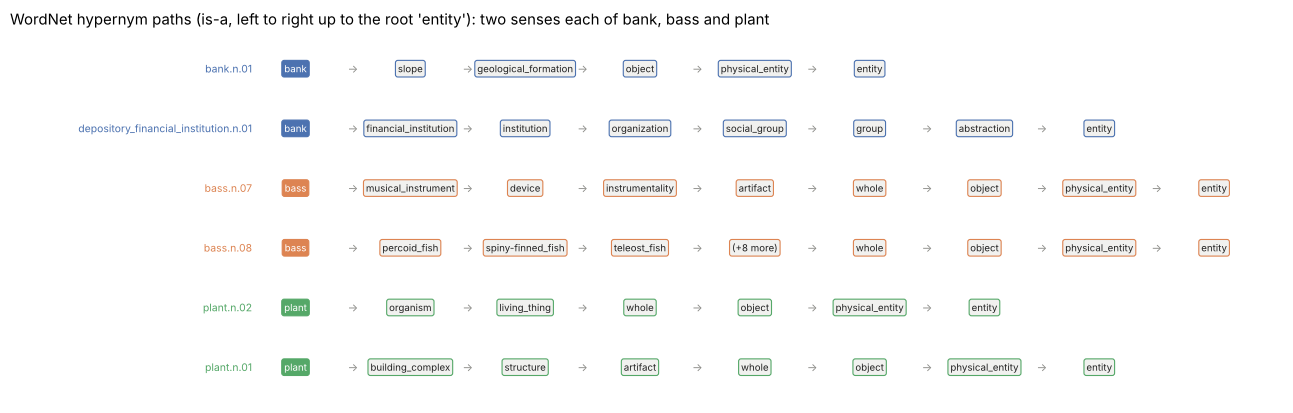

bank.n.01                                depth  5: bank > slope > geological_formation > object > ...
depository_financial_institution.n.01    depth  7: depository_financial_institution > financial_institution > institution > organization > ...
bass.n.07                                depth  8: bass > musical_instrument > device > instrumentality > ...
bass.n.08                                depth 15: bass > percoid_fish > spiny-finned_fish > teleost_fish > ...
plant.n.02                               depth  6: plant > organism > living_thing > whole > ...
plant.n.01                               depth  7: plant > building_complex > structure > artifact > ...


In [5]:
def hypernym_chain(s):
    path = s.hypernym_paths()[0]
    return list(reversed(path))          # sense -> ... -> entity

chains = {n: hypernym_chain(wn.synset(n)) for n in ["bank.n.01", "depository_financial_institution.n.01", "bass.n.07", "bass.n.08", "plant.n.02", "plant.n.01"]}
fig, ax = plt.subplots(figsize=(13, 4.2))
colors = ["#4c72b0", "#4c72b0", "#dd8452", "#dd8452", "#55a868", "#55a868"]
STEP = 1.85
for r, (name, chain) in enumerate(chains.items()):
    y = len(chains) - 1 - r
    head = "bank" if name.startswith("depository") else name.split(".")[0]      # the ambiguous word itself
    labels = [head] + [c.name().split(".")[0] for c in chain[1:]]
    if len(labels) > 9:                                    # long chains (the fish) are shortened in the middle
        labels = labels[:4] + [f"(+{len(labels) - 8} more)"] + labels[-4:]
    for i, lab in enumerate(labels):
        ax.text(i * STEP, y, lab, ha="center", va="center", fontsize=7, color="white" if i == 0 else "#222",
                bbox=dict(boxstyle="round,pad=0.25", fc=colors[r] if i == 0 else "#f1f1ef", ec=colors[r], lw=0.8))
        if i:
            ax.text((i - 0.5) * STEP, y, "→", ha="center", va="center", fontsize=8, color="#8a8a86")
    ax.text(-0.7, y, name, ha="right", va="center", fontsize=7.5, color=colors[r])
ax.set_xlim(-4.6, 8.6 * STEP); ax.set_ylim(-0.6, len(chains) - 0.4); ax.axis("off")
ax.set_title("WordNet hypernym paths (is-a, left to right up to the root 'entity'): two senses each of bank, bass and plant", loc="left")
plt.tight_layout(); fig.savefig(OUT / "hypernym_paths.png", dpi=200, bbox_inches="tight"); plt.show()
for n, c in chains.items():
    print(f"{n:<40} depth {len(c) - 1:>2}: " + " > ".join(x.name().split(".")[0] for x in c[:4]) + " > ...")

In [6]:
# Semantic similarity: each sense of 'bank' against words that typically appear near it
probes = {"river.n.01": "river", "money.n.01": "money", "loan.n.01": "loan", "shore.n.01": "shore", "slope.n.01": "slope"}
sim_rows = []
for s in [wn.synset("bank.n.01"), wn.synset("depository_financial_institution.n.01"), wn.synset("bank.n.03"), wn.synset("bank.n.07")]:
    sim_rows.append({"bank sense": s.name(), **{f"{w} (WuP / path)": f"{s.wup_similarity(wn.synset(n)):.2f} / {s.path_similarity(wn.synset(n)):.2f}"
                                                for n, w in probes.items()}})
print("Wu-Palmer and path similarity between senses of 'bank' and context words:")
pd.DataFrame(sim_rows)

Wu-Palmer and path similarity between senses of 'bank' and context words:


,bank sense,river (WuP / path),money (WuP / path),loan (WuP / path),shore (WuP / path),slope (WuP / path)
0,bank.n.01,0.33 / 0.11,0.15 / 0.08,0.15 / 0.08,0.73 / 0.25,0.91 / 0.50
1,depository_financial_institution.n.01,0.14 / 0.08,0.27 / 0.08,0.27 / 0.08,0.15 / 0.08,0.15 / 0.08
2,bank.n.03,0.31 / 0.10,0.14 / 0.08,0.14 / 0.08,0.67 / 0.20,0.67 / 0.20
3,bank.n.07,0.33 / 0.11,0.15 / 0.08,0.15 / 0.08,0.73 / 0.25,0.91 / 0.50


## 3. WSD algorithms

All methods receive the **target lemma**, its part of speech and the **context**: the content words of the sentence, lemmatised and without stop words. They return one WordNet synset.

| Method | Idea | Uses |
|---|---|---|
| **Random** | pick any sense of the word | lower bound |
| **MFS** | always pick WordNet's first sense (most frequent in SemCor) | sense frequency; a strong baseline |
| **Simplified Lesk (NLTK)** | pick the sense whose gloss shares the most words with the context (Lesk, 1986) | gloss only |
| **Extended Lesk (ours)** | a sense's *signature* = its gloss + examples + synonyms, plus the glosses and names of its hypernyms, hyponyms, meronyms, holonyms, similar/also-see words, entailments and derived forms. Overlap with the context is weighted by **IDF**, so rare shared words count more than common ones; with no overlap at all, fall back to MFS | gloss + lexical relations + frequency |
| **Similarity (Wu–Palmer)** | pick the sense most related to the context: for each context word, take its best Wu–Palmer similarity with the candidate sense, then sum over context words (Pedersen et al., 2005) | the hypernym hierarchy |

Simple Lesk fails when the gloss is short: *bank.n.01* is just "sloping land (especially the slope beside a body of water)". It contains neither *river* nor *fish*. Extended Lesk adds the definitions of related synsets, such as *slope*, *riverbank* and *waterside*, so a context about a river has something to overlap with.

In [7]:
lemmatizer = WordNetLemmatizer()
STOP = set(stopwords.words("english")) | {"one", "use", "used", "make", "made", "also", "etc", "especially", "usually", "something", "someone"}
PTB2WN = {"N": wn.NOUN, "V": wn.VERB, "J": wn.ADJ, "R": wn.ADV}

def content_words(tokens_with_tags):
    """[(token, PTB tag)] -> [(lemma, wn_pos)] for content words."""
    out = []
    for tok, tag in tokens_with_tags:
        p = PTB2WN.get(tag[:1])
        t = tok.lower()
        if p and t.isalpha() and t not in STOP and len(t) > 1:
            out.append((lemmatizer.lemmatize(t, p), p))
    return out

def gloss_tokens(text):
    return [lemmatizer.lemmatize(t) for t in re.findall(r"[a-z]+", text.lower()) if t not in STOP and len(t) > 1]

def related_synsets(s):
    rel = (s.hypernyms() + s.instance_hypernyms() + s.hyponyms()[:10] + s.part_meronyms() + s.member_meronyms() +
           s.substance_meronyms() + s.part_holonyms() + s.member_holonyms() + s.substance_holonyms() +
           s.similar_tos() + s.also_sees() + s.entailments() + s.verb_groups() + s.attributes())
    rel += [d.synset() for l in s.lemmas() for d in l.derivationally_related_forms()]
    return list(dict.fromkeys(rel))

_sig_cache = {}
def signature_parts(s):
    """(own words, relative words): own = gloss, examples, synonyms; relatives = glosses and names of related synsets."""
    if s.name() not in _sig_cache:
        own = set(gloss_tokens(s.definition()) + [w for e in s.examples() for w in gloss_tokens(e)] +
                  [w for l in s.lemmas() for w in l.name().lower().split("_")]) - STOP
        rel = set()
        for r in related_synsets(s):
            rel |= set(gloss_tokens(r.definition()) + [w for l in r.lemmas() for w in l.name().lower().split("_")])
        _sig_cache[s.name()] = (own, rel - own - STOP)
    return _sig_cache[s.name()]

def signature(s, extended=True):
    own, rel = signature_parts(s)
    return own | rel if extended else own

# IDF of words over all WordNet glosses: rare gloss words are better evidence than frequent ones
_df = Counter()
for _s in wn.all_synsets():
    _df.update(set(gloss_tokens(_s.definition())))
N_GLOSSES = sum(1 for _ in wn.all_synsets())
IDF = defaultdict(lambda: math.log(N_GLOSSES), {w: math.log(N_GLOSSES / c) for w, c in _df.items()})

def candidates(lemma, pos):
    p = [wn.ADJ, wn.ADJ_SAT] if pos in (wn.ADJ, wn.ADJ_SAT) else [pos]
    return [s for s in wn.synsets(lemma) if s.pos() in p]

def wsd_random(lemma, pos, context, rng=random.Random(SEED)):
    c = candidates(lemma, pos); return rng.choice(c) if c else None

def wsd_mfs(lemma, pos, context):
    c = candidates(lemma, pos); return c[0] if c else None

def wsd_simple_lesk(lemma, pos, context):
    sent = [w for w, _ in context]
    return nltk_lesk(sent, lemma, pos="a" if pos == wn.ADJ_SAT else pos)

def wsd_extended_lesk(lemma, pos, context, w_rel=1.0, idf=True, prior=0.0, return_scores=False):
    """score(sense) = sum of IDF of context words found in its own gloss words
                      + w_rel * same for words of related synsets + prior * log(1 + SemCor count)."""
    cands = candidates(lemma, pos)
    if not cands:
        return None
    ctx = {w for w, _ in context if w != lemma}
    wt = (lambda w: IDF[w]) if idf else (lambda w: 1.0)
    scores = []
    for s in cands:
        own, rel = signature_parts(s)
        sc = sum(wt(w) for w in sorted(ctx & own)) + w_rel * sum(wt(w) for w in sorted(ctx & rel))
        scores.append(sc + prior * math.log1p(lemma_count(s, lemma)))
    best = int(np.argmax(scores)) if max(scores) > 0 else 0        # ties -> more frequent sense; no overlap -> MFS
    return (cands[best], {c.name(): round(float(v), 1) for c, v in zip(cands, scores)}) if return_scores else cands[best]

def wsd_similarity(lemma, pos, context, window=6, senses_per_word=3):
    cands = candidates(lemma, pos)
    if not cands:
        return None
    if pos not in (wn.NOUN, wn.VERB):                       # Wu-Palmer needs a hypernym hierarchy
        return cands[0]
    ctx = [w for w, p in context if p == pos and w != lemma][:window]
    ctx_senses = [wn.synsets(w, pos)[:senses_per_word] for w in ctx]
    scores = []
    for s in cands:
        total = 0.0
        for cs in ctx_senses:
            sims = [s.wup_similarity(c) or 0.0 for c in cs]
            total += max(sims) if sims else 0.0
        scores.append(total)
    return cands[int(np.argmax(scores))] if max(scores) > 0 else cands[0]

METHODS = {"Random": wsd_random, "MFS": wsd_mfs, "Simplified Lesk (NLTK)": wsd_simple_lesk,
           "Extended Lesk (ours)": wsd_extended_lesk, "Similarity (Wu-Palmer)": wsd_similarity}

def context_of(sentence):
    return content_words(pos_tag(word_tokenize(sentence)))

s0 = "He sat on the bank of the river and watched the water flow past."
best, sc = wsd_extended_lesk("bank", "n", context_of(s0), return_scores=True)
print(s0)
print("extended Lesk scores:", {k: v for k, v in sc.items() if v > 0}, "->", best.name(), "|", best.definition())
print("simplified Lesk (NLTK):", wsd_simple_lesk("bank", "n", context_of(s0)).name())
print(f"signature sizes for bank.n.01: gloss-only {len(signature(wn.synset('bank.n.01'), False))} words, "
      f"extended {len(signature(wn.synset('bank.n.01')))} words")

He sat on the bank of the river and watched the water flow past.
extended Lesk scores: {'bank.n.01': 9.8, 'bank.n.03': 5.3} -> bank.n.01 | sloping land (especially the slope beside a body of water)
simplified Lesk (NLTK): bank.n.01
signature sizes for bank.n.01: gloss-only 13 words, extended 23 words


## 4. Applying WSD to sample sentences

Each target word is used in two sentences written for this lab, one for each of its main senses. The gold sense was chosen by hand from the inventory in §1. Where two WordNet synsets fit equally well (WordNet is very fine-grained), both are accepted.

In [8]:
SAMPLES = [
    ("bank", "n", "He sat on the bank of the river and watched the water flow past.", {"bank.n.01"}),
    ("bank", "n", "She deposited her salary at the bank and asked the manager about a loan.", {"depository_financial_institution.n.01"}),
    ("bass", "n", "He caught a huge bass while fishing in the lake.", {"bass.n.08", "freshwater_bass.n.01"}),
    ("bass", "n", "The band's bass player tuned his instrument before the concert.", {"bass.n.07"}),
    ("plant", "n", "The chemical plant employs hundreds of factory workers.", {"plant.n.01"}),
    ("plant", "n", "Water the plant every day so that its leaves and roots stay healthy.", {"plant.n.02"}),
    ("crane", "n", "A crane lifted the heavy steel beams onto the building.", {"crane.n.04"}),
    ("crane", "n", "The crane waded through the marsh looking for fish with its long neck.", {"crane.n.05"}),
    ("interest", "n", "The bank raised the interest rate on loans to five percent.", {"interest.n.04"}),
    ("interest", "n", "She showed great interest in astronomy and curiosity about the stars.", {"interest.n.01"}),
    ("line", "n", "There was a long line of people waiting outside the theatre.", {"line.n.03", "line.n.01"}),
    ("line", "n", "The telephone line went dead during the storm.", {"telephone_line.n.02"}),
    ("serve", "v", "The waiter will serve dinner and drinks to the guests.", {"serve.v.05", "serve.v.06"}),
    ("serve", "v", "He served two terms as mayor of the city.", {"serve.v.02"}),
    ("hard", "a", "The exam was very hard and few students could solve the problems.", {"difficult.a.01"}),
    ("hard", "a", "The diamond is a hard stone that resists pressure and scratching.", {"hard.a.03"}),
]
rows, hits = [], Counter()
for word, p, sent, gold in SAMPLES:
    ctx = context_of(sent)
    row = {"target": word, "sentence": sent[:62] + ("…" if len(sent) > 62 else ""), "gold": "/".join(sorted(gold))}
    for m, f in METHODS.items():
        if m == "Random":
            continue
        pred = f(word, p, ctx)
        ok = pred is not None and pred.name() in gold
        hits[m] += ok
        row[m] = (pred.name() if pred else "—") + (" ✓" if ok else " ✗")
    rows.append(row)
SAMPLE_RESULTS = pd.DataFrame(rows)
display(SAMPLE_RESULTS)
print("Correct out of", len(SAMPLES), ":", {m: hits[m] for m in METHODS if m != "Random"})

,target,sentence,gold,MFS,Simplified Lesk (NLTK),Extended Lesk (ours),Similarity (Wu-Palmer)
0,bank,He sat on the bank of the river and watched the water flow pas…,bank.n.01,bank.n.01 ✓,bank.n.01 ✓,bank.n.01 ✓,bank.n.06 ✗
1,bank,She deposited her salary at the bank and asked the manager abo…,depository_financial_institution.n.01,bank.n.01 ✗,bank.n.01 ✗,depository_financial_institution.n.01 ✓,bank.n.06 ✗
2,bass,He caught a huge bass while fishing in the lake.,bass.n.08/freshwater_bass.n.01,bass.n.01 ✗,sea_bass.n.01 ✗,sea_bass.n.01 ✗,sea_bass.n.01 ✗
3,bass,The band's bass player tuned his instrument before the concert…,bass.n.07,bass.n.01 ✗,bass.n.01 ✗,bass.n.02 ✗,bass.n.03 ✗
4,plant,The chemical plant employs hundreds of factory workers.,plant.n.01,plant.n.01 ✓,plant.n.01 ✓,plant.n.01 ✓,plant.n.01 ✓
5,plant,Water the plant every day so that its leaves and roots stay he…,plant.n.02,plant.n.01 ✗,plant.n.01 ✗,plant.n.01 ✗,plant.n.02 ✓
6,crane,A crane lifted the heavy steel beams onto the building.,crane.n.04,crane.n.01 ✗,crane.n.04 ✓,crane.n.04 ✓,crane.n.04 ✓
7,crane,The crane waded through the marsh looking for fish with its lo…,crane.n.05,crane.n.01 ✗,crane.n.01 ✗,crane.n.05 ✓,crane.n.01 ✗
8,interest,The bank raised the interest rate on loans to five percent.,interest.n.04,interest.n.01 ✗,interest.n.01 ✗,interest.n.01 ✗,interest.n.04 ✓
9,interest,She showed great interest in astronomy and curiosity about the…,interest.n.01,interest.n.01 ✓,interest.n.01 ✓,interest.n.03 ✗,interest.n.01 ✓


Correct out of 16 : {'MFS': 5, 'Simplified Lesk (NLTK)': 8, 'Extended Lesk (ours)': 10, 'Similarity (Wu-Palmer)': 7}


In [9]:
def annotate(sentence):
    """Full annotation of a sentence: every content word that has WordNet senses gets an extended-Lesk sense."""
    tagged = pos_tag(word_tokenize(sentence))
    ctx = content_words(tagged)
    out = []
    for tok, tag in tagged:
        p = PTB2WN.get(tag[:1])
        lem = lemmatizer.lemmatize(tok.lower(), p) if p else tok.lower()
        s = wsd_extended_lesk(lem, p, ctx) if p and tok.isalpha() and tok.lower() not in STOP else None
        out.append({"token": tok, "POS": tag, "lemma": lem, "senses": len(candidates(lem, p)) if s else 0,
                    "synset": s.name() if s else "", "gloss": s.definition()[:70] if s else ""})
    return out

ann_rows = [dict(sentence_id=i, **a) for i, (_, _, sent, _) in enumerate(SAMPLES) for a in annotate(sent)]
ANNOTATIONS = pd.DataFrame(ann_rows)
ANNOTATIONS.to_csv(OUT / "sample_annotations.csv", index=False)
print("full sense annotation of all sample sentences -> outputs/sample_annotations.csv; e.g. sentence 1:")
ANNOTATIONS[(ANNOTATIONS.sentence_id == 1) & (ANNOTATIONS.synset != "")][["token", "POS", "lemma", "senses", "synset", "gloss"]]

full sense annotation of all sample sentences -> outputs/sample_annotations.csv; e.g. sentence 1:


,token,POS,lemma,senses,synset,gloss
16,deposited,VBD,deposit,3,deposit.v.02,put into a bank account
18,salary,NN,salary,1,wage.n.01,something that remunerates
21,bank,NN,bank,10,depository_financial_institution.n.01,a financial institution that accepts deposits and channels the money i
23,asked,VBD,ask,7,ask.v.02,make a request or demand for something to somebody
25,manager,NN,manager,2,director.n.01,someone who controls resources and expenditures
28,loan,NN,loan,2,loan.n.01,the temporary provision of money (usually at interest)


## 5. Evaluation on SemCor (all-words WSD)

**SemCor** (Miller et al., 1993) is part of the Brown Corpus in which every content word was tagged by hand with its WordNet sense. It is the standard benchmark for WordNet-based WSD. The evaluation uses the first **10 files of the `brown1` part** and disambiguates every tagged noun, verb, adjective and adverb. Proper names are skipped.

Setup, as in most all-words evaluations:
* The gold **lemma and part of speech are given**; only the sense has to be chosen.
* The context is all content words of the sentence.
* Accuracy is reported on **all** instances and on the **ambiguous** ones (two or more senses), because unambiguous words are trivially correct.

**Caveat.** WordNet's sense order and `lemma.count()` were derived from SemCor itself, so MFS is slightly optimistic here. The supervised comparison in §6 uses different data.

In [10]:
POSMAP = {"n": wn.NOUN, "v": wn.VERB, "a": wn.ADJ, "s": wn.ADJ, "r": wn.ADV}
FILES = sorted(f for f in semcor.fileids() if f.startswith("brown1"))[:10]

def semcor_instances(fileids):
    insts = []
    for f in fileids:
        for sid, sent in enumerate(semcor.tagged_sents(fileids=f, tag="both")):
            tokens, targets = [], []
            for chunk in sent:
                if not hasattr(chunk, "label"):
                    continue
                lab = chunk.label()
                inner = chunk[0] if len(chunk) and hasattr(chunk[0], "label") else None
                tag = inner.label() if inner is not None else lab
                words = inner.leaves() if inner is not None else chunk.leaves()
                is_ne = tag == "NE" or (inner is not None and inner.label() == "NE")
                if is_ne and inner is not None and len(inner) and hasattr(inner[0], "label"):
                    tag = inner[0].label()
                tokens += [(w, tag if isinstance(tag, str) else "NN") for w in words]
                if hasattr(lab, "synset") and not is_ne:
                    targets.append((lab.name().lower(), POSMAP.get(lab.synset().pos()), lab.synset()))
            ctx = content_words(tokens)
            for lemma, p, gold in targets:
                if p and candidates(lemma, p):
                    insts.append({"file": f.split("/")[-1], "sent": sid, "lemma": lemma, "pos": p, "gold": gold,
                                  "n_senses": len(candidates(lemma, p)), "context": ctx})
    return insts

t0 = time.time()
SEMCOR = semcor_instances(FILES)
amb = [x for x in SEMCOR if x["n_senses"] > 1]
print(f"{len(SEMCOR)} tagged instances from {len(FILES)} files ({len(amb)} ambiguous, mean {np.mean([x['n_senses'] for x in amb]):.1f} senses each); "
      f"loaded in {time.time() - t0:.0f} s")
print(Counter(x["pos"] for x in SEMCOR))

8814 tagged instances from 10 files (6881 ambiguous, mean 7.8 senses each); loaded in 2 s
Counter({'n': 4133, 'v': 2367, 'a': 1577, 'r': 737})


In [11]:
results = {}
for m, f in METHODS.items():
    t0 = time.time()
    preds = [f(x["lemma"], x["pos"], x["context"]) for x in SEMCOR]
    results[m] = [p is not None and p == x["gold"] for p, x in zip(preds, SEMCOR)]
    print(f"{m:<26} done in {time.time() - t0:5.1f} s")
for variant, kw in [("Lesk: own gloss only + IDF", dict(w_rel=0.0)),
                    ("Lesk: extended, no IDF", dict(idf=False))]:
    results[variant] = [wsd_extended_lesk(x["lemma"], x["pos"], x["context"], **kw) == x["gold"] for x in SEMCOR]

is_amb = np.array([x["n_senses"] > 1 for x in SEMCOR])
pos_arr = np.array([x["pos"] for x in SEMCOR])
SEMCOR_RES = pd.DataFrame({m: {"all instances": np.mean(r), "ambiguous only": np.mean(np.array(r)[is_amb]),
                               **{f"{name}": np.mean(np.array(r)[is_amb & (pos_arr == p)]) for p, name in
                                  [(wn.NOUN, "nouns"), (wn.VERB, "verbs"), (wn.ADJ, "adjectives"), (wn.ADV, "adverbs")]}}
                           for m, r in results.items()}).T.round(3)
SEMCOR_RES.insert(0, "instances", len(SEMCOR))
SEMCOR_RES.to_csv(OUT / "semcor_results.csv")
print("Accuracy on SemCor (POS columns: ambiguous instances only):")
SEMCOR_RES

Random                     done in   0.1 s
MFS                        done in   0.1 s
Simplified Lesk (NLTK)     done in   0.2 s
Extended Lesk (ours)       done in   8.6 s
Similarity (Wu-Palmer)     done in  52.6 s
Accuracy on SemCor (POS columns: ambiguous instances only):


,instances,all instances,ambiguous only,nouns,verbs,adjectives,adverbs
Random,8814,0.396,0.226,0.260,0.140,0.278,0.295
MFS,8814,0.737,0.663,0.701,0.549,0.765,0.743
Simplified Lesk (NLTK),8814,0.558,0.504,0.553,0.408,0.469,0.720
Extended Lesk (ours),8814,0.650,0.551,0.603,0.400,0.664,0.687
Similarity (Wu-Palmer),8814,0.579,0.460,0.385,0.377,0.765,0.743
Lesk: own gloss only + IDF,8814,0.677,0.586,0.637,0.451,0.681,0.687
"Lesk: extended, no IDF",8814,0.662,0.568,0.617,0.421,0.680,0.700


### Combining Lesk with sense frequency

MFS is hard to beat on SemCor, because most words in running text are used in their most frequent sense (Navigli, 2009). The natural improvement is to **combine the two kinds of evidence**: add a frequency prior λ·log(1 + SemCor count) to the extended-Lesk score, and give the words of related synsets a weight w_rel. Both parameters are tuned on **10 different SemCor files** (`brown1` files 11–20, a development set), never on the 10 test files, and the best setting is then applied once to the test files and to the sample sentences.

In [12]:
DEV_FILES = sorted(f for f in semcor.fileids() if f.startswith("brown1"))[10:20]
DEV = [x for x in semcor_instances(DEV_FILES) if x["n_senses"] > 1]
grid = []
for w_rel in [0.0, 0.25, 0.5, 1.0]:
    for prior in [0.0, 5.0, 10.0, 20.0]:
        acc = np.mean([wsd_extended_lesk(x["lemma"], x["pos"], x["context"], w_rel=w_rel, prior=prior) == x["gold"] for x in DEV])
        grid.append({"w_rel": w_rel, "prior λ": prior, "dev accuracy": round(acc, 4)})
GRID = pd.DataFrame(grid)
best = GRID.loc[GRID["dev accuracy"].idxmax()]
BEST_WREL, BEST_PRIOR = float(best["w_rel"]), float(best["prior λ"])
mfs_dev = np.mean([wsd_mfs(x["lemma"], x["pos"], x["context"]) == x["gold"] for x in DEV])
print(f"development set: {len(DEV)} ambiguous instances; MFS {mfs_dev:.3f}; best: w_rel = {BEST_WREL}, λ = {BEST_PRIOR} "
      f"-> {best['dev accuracy']:.3f}")
display(GRID.pivot(index="w_rel", columns="prior λ", values="dev accuracy"))

def wsd_lesk_prior(lemma, pos, context):
    return wsd_extended_lesk(lemma, pos, context, w_rel=BEST_WREL, prior=BEST_PRIOR)
METHODS["Extended Lesk + prior (tuned)"] = wsd_lesk_prior
r = [wsd_lesk_prior(x["lemma"], x["pos"], x["context"]) == x["gold"] for x in SEMCOR]
results["Extended Lesk + prior (tuned)"] = r
SEMCOR_RES.loc["Extended Lesk + prior (tuned)"] = [len(SEMCOR), np.mean(r), np.mean(np.array(r)[is_amb])] + \
    [np.mean(np.array(r)[is_amb & (pos_arr == p)]) for p in [wn.NOUN, wn.VERB, wn.ADJ, wn.ADV]]
SEMCOR_RES = SEMCOR_RES.round(3)
SEMCOR_RES["instances"] = SEMCOR_RES["instances"].astype(int)
SEMCOR_RES.to_csv(OUT / "semcor_results.csv")
n_ok = sum(wsd_lesk_prior(w, p, context_of(s)).name() in g for w, p, s, g in SAMPLES)
print(f"test files: {np.mean(np.array(r)[is_amb]):.3f} on ambiguous instances (MFS {SEMCOR_RES.loc['MFS', 'ambiguous only']:.3f}); "
      f"sample sentences: {n_ok}/{len(SAMPLES)} correct")
SEMCOR_RES

development set: 7899 ambiguous instances; MFS 0.660; best: w_rel = 0.25, λ = 20.0 -> 0.669


prior λ,0.0,5.0,10.0,20.0
w_rel,,,,
0.00,0.5667,0.6607,0.6667,0.6669
0.25,0.5187,0.6631,0.6691,0.6693
0.50,0.5196,0.6649,0.6686,0.6691
1.00,0.5270,0.6541,0.6681,0.6678


test files: 0.672 on ambiguous instances (MFS 0.663); sample sentences: 8/16 correct


,instances,all instances,ambiguous only,nouns,verbs,adjectives,adverbs
Random,8814,0.396,0.226,0.260,0.140,0.278,0.295
MFS,8814,0.737,0.663,0.701,0.549,0.765,0.743
Simplified Lesk (NLTK),8814,0.558,0.504,0.553,0.408,0.469,0.720
Extended Lesk (ours),8814,0.650,0.551,0.603,0.400,0.664,0.687
Similarity (Wu-Palmer),8814,0.579,0.460,0.385,0.377,0.765,0.743
Lesk: own gloss only + IDF,8814,0.677,0.586,0.637,0.451,0.681,0.687
"Lesk: extended, no IDF",8814,0.662,0.568,0.617,0.421,0.680,0.700
Extended Lesk + prior (tuned),8814,0.744,0.672,0.711,0.555,0.781,0.743


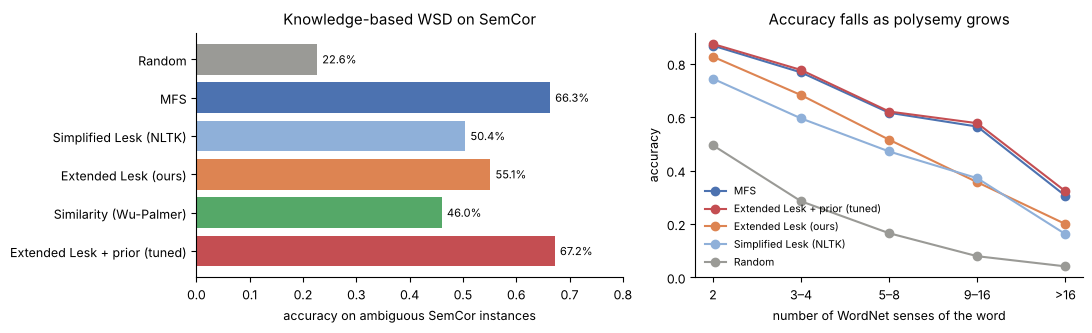

In [13]:
main = ["Random", "MFS", "Simplified Lesk (NLTK)", "Extended Lesk (ours)", "Similarity (Wu-Palmer)", "Extended Lesk + prior (tuned)"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [1.1, 1]})
vals = SEMCOR_RES.loc[main, "ambiguous only"]
ax[0].barh(main[::-1], vals[::-1], color=["#9a9a96", "#4c72b0", "#8fb0d9", "#dd8452", "#55a868", "#c44e52"][::-1])
for i, v in enumerate(vals[::-1]):
    ax[0].text(v + 0.01, i, f"{v:.1%}", va="center", fontsize=8)
ax[0].set_xlim(0, 0.8); ax[0].set_xlabel("accuracy on ambiguous SemCor instances"); ax[0].set_title("Knowledge-based WSD on SemCor")
bins = pd.cut([x["n_senses"] for x in SEMCOR], [1, 2, 4, 8, 16, 100], labels=["2", "3–4", "5–8", "9–16", ">16"])
for m, c in [("MFS", "#4c72b0"), ("Extended Lesk + prior (tuned)", "#c44e52"), ("Extended Lesk (ours)", "#dd8452"), ("Simplified Lesk (NLTK)", "#8fb0d9"), ("Random", "#9a9a96")]:
    acc = pd.Series(results[m])[is_amb].groupby(bins[is_amb], observed=False).mean()
    ax[1].plot(acc.index.astype(str), acc.values, "o-", color=c, label=m)
ax[1].set_xlabel("number of WordNet senses of the word"); ax[1].set_ylabel("accuracy")
ax[1].set_title("Accuracy falls as polysemy grows"); ax[1].legend(frameon=False, fontsize=7.5)
plt.tight_layout(); fig.savefig(OUT / "semcor_accuracy.png", dpi=200, bbox_inches="tight"); plt.show()

## 6. Supervised WSD on the line / interest / serve / hard corpora

Knowledge-based methods need only a dictionary. **Supervised** WSD instead learns from examples that were labelled by hand. NLTK's `senseval` corpus contains four classic *lexical-sample* data sets: thousands of contexts for each of the words *line* (6 senses; Leacock et al., 1993), *interest* (6 senses; Bruce & Wiebe, 1994), *serve* (4 senses) and *hard* (3 senses). The senses are coarser than WordNet's.

**Features** (Yarowsky-style, all from the context of the target word):
* **bag of words:** lemmas of the content words within ±10 tokens;
* **local collocations:** the words immediately to the left and right, and the two-word sequences around the target (*w-1*, *w+1*, *w-2 w-1*, *w+1 w+2*);
* **local part-of-speech tags** (*p-1*, *p+1*) and the target's own inflected form (*lines* vs *line*).

**Models:** a most-frequent-sense baseline, multinomial **Naive Bayes** and **logistic regression**, all scored with **stratified 5-fold cross-validation**.

In [14]:
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict, learning_curve
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline

SV_FILES = {"line": ("line.pos", wn.NOUN), "interest": ("interest.pos", wn.NOUN), "serve": ("serve.pos", wn.VERB), "hard": ("hard.pos", wn.ADJ)}

def tok_tag(t):
    return t if isinstance(t, tuple) else (t, "NN")

def sv_features(inst, window=10):
    ctx = [tok_tag(t) for t in inst.context]
    p = inst.position
    w = lambda i: ctx[i][0].lower() if 0 <= i < len(ctx) else "<s>"
    t = lambda i: ctx[i][1] if 0 <= i < len(ctx) else "<s>"
    f = {"w-1=" + w(p - 1): 1, "w+1=" + w(p + 1): 1, "w-2w-1=" + w(p - 2) + "_" + w(p - 1): 1,
         "w+1w+2=" + w(p + 1) + "_" + w(p + 2): 1, "p-1=" + t(p - 1): 1, "p+1=" + t(p + 1): 1, "form=" + w(p): 1}
    for lem, _ in content_words(ctx[max(0, p - window):p] + ctx[p + 1:p + 1 + window]):
        f["bow=" + lem] = f.get("bow=" + lem, 0) + 1
    return f

SV = {}
for word, (fid, p) in SV_FILES.items():
    insts = senseval.instances(fid)
    SV[word] = {"X": [sv_features(i) for i in insts], "y": np.array([i.senses[0] for i in insts]), "insts": insts, "pos": p}
    print(f"{word:<9} {len(insts):>5} instances, senses: " +
          ", ".join(f"{s} {c / len(insts):.0%}" for s, c in Counter(SV[word]['y']).most_common()))

line       4146 instances, senses: product 53%, phone 10%, text 10%, division 9%, cord 9%, formation 8%
interest   2368 instances, senses: interest_6 53%, interest_5 21%, interest_1 15%, interest_4 8%, interest_3 3%, interest_2 0%
serve      4378 instances, senses: SERVE10 41%, SERVE12 29%, SERVE2 19%, SERVE6 10%
hard       4333 instances, senses: HARD1 80%, HARD2 12%, HARD3 9%


In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
MODELS = {"MFS baseline": lambda: DummyClassifier(strategy="most_frequent"),
          "Naive Bayes": lambda: MultinomialNB(alpha=0.3),
          "Logistic regression": lambda: LogisticRegression(C=2.0, max_iter=3000)}
sup_rows, PRED = [], {}
for word, d in SV.items():
    for name, mk in MODELS.items():
        pipe = make_pipeline(DictVectorizer(), mk())
        pred = cross_val_predict(pipe, d["X"], d["y"], cv=cv)
        PRED[(word, name)] = pred
        sup_rows.append({"word": word, "model": name, "accuracy": accuracy_score(d["y"], pred),
                         "macro-F1": f1_score(d["y"], pred, average="macro")})
SUP = pd.DataFrame(sup_rows)
SUP_TABLE = SUP.pivot(index="model", columns="word", values="accuracy").loc[list(MODELS)]
SUP_TABLE["mean"] = SUP_TABLE.mean(axis=1)
SUP_F1 = SUP.pivot(index="model", columns="word", values="macro-F1").loc[list(MODELS)]
SUP_F1["mean"] = SUP_F1.mean(axis=1)
SUP.to_csv(OUT / "supervised_results.csv", index=False)
print("Accuracy (5-fold cross-validation):"); display(SUP_TABLE.round(3))
print("Macro-F1 (treats rare senses as equally important):"); SUP_F1.round(3)

Accuracy (5-fold cross-validation):


word,hard,interest,line,serve,mean
model,,,,,
MFS baseline,0.797,0.529,0.535,0.414,0.569
Naive Bayes,0.931,0.932,0.891,0.922,0.919
Logistic regression,0.928,0.935,0.874,0.929,0.916


Macro-F1 (treats rare senses as equally important):


word,hard,interest,line,serve,mean
model,,,,,
MFS baseline,0.296,0.115,0.116,0.146,0.168
Naive Bayes,0.854,0.720,0.841,0.907,0.831
Logistic regression,0.840,0.721,0.821,0.915,0.824


### Knowledge-based methods on the same data

The corpus senses can be mapped onto WordNet synsets by comparing glosses with example contexts. The mapping below is our own, made for *line*, *interest* and *serve*; *hard* is left out because its corpus senses do not line up cleanly with WordNet's adjective senses. A knowledge-based prediction counts as correct when it falls in the synset set of the gold sense. The knowledge-based methods use no training data at all, so this comparison shows what labelled examples are worth.

Two settings are reported:
* **open:** the method chooses among *all* WordNet senses of the word, 30 for *line*;
* **mapped senses only:** it chooses only among the synsets that correspond to a corpus sense. This tells the method which senses are possible, as the classifier implicitly knows.

In [16]:
SENSE_MAP = {
    "line": {"cord": ["line.n.18"], "division": ["line.n.29"], "formation": ["line.n.03", "line.n.01"],
             "phone": ["telephone_line.n.02"], "product": ["line.n.22"], "text": ["line.n.05"]},
    "interest": {"interest_1": ["interest.n.01"], "interest_2": ["interest.n.03"], "interest_3": ["interest.n.06"],
                 "interest_4": ["sake.n.01"], "interest_5": ["interest.n.05"], "interest_6": ["interest.n.04"]},
    "serve": {"SERVE10": ["serve.v.05", "serve.v.06"], "SERVE12": ["serve.v.02"], "SERVE2": ["serve.v.01"], "SERVE6": ["service.v.01"]},
}
print("Sense mapping (corpus sense -> WordNet synsets):")
for w, m in SENSE_MAP.items():
    print(f"  {w}: " + "; ".join(f"{k} -> {'/'.join(v)} ({wn.synset(v[0]).definition()[:38]}…)" for k, v in m.items()))

kb_rows = []
for word, m in SENSE_MAP.items():
    d = SV[word]
    ctxs = [content_words([tok_tag(t) for t in i.context[max(0, i.position - 15):i.position + 16]]) for i in d["insts"]]
    for name in ["MFS", "Simplified Lesk (NLTK)", "Extended Lesk (ours)", "Extended Lesk + prior (tuned)"]:  # open setting
        f = METHODS[name]
        preds = [f(word, d["pos"], c) for c in ctxs]
        acc = np.mean([pr is not None and pr.name() in m[g] for pr, g in zip(preds, d["y"])])
        kb_rows.append({"method": name + " (WordNet)", "word": word, "accuracy": acc})
    # restricted variant: choose only among the WordNet synsets that correspond to a corpus sense
    allowed = [syn for v in m.values() for syn in v]
    inv = {syn: g for g, v in m.items() for syn in v}
    prior_pick = max(allowed, key=lambda n: lemma_count(wn.synset(n), word))
    for name, prior in [("Extended Lesk, mapped senses only", 0.0)]:
        correct = 0
        for c, g in zip(ctxs, d["y"]):
            if prior is None:
                pick = prior_pick
            else:
                sc = wsd_extended_lesk(word, d["pos"], c, return_scores=True)[1]
                best_n = max(allowed, key=lambda n: (sc.get(n, 0), lemma_count(wn.synset(n), word)))
                pick = best_n if sc.get(best_n, 0) > 0 else prior_pick
            correct += inv[pick] == g
        kb_rows.append({"method": name + " (WordNet)", "word": word, "accuracy": correct / len(ctxs)})
KB = pd.DataFrame(kb_rows).pivot(index="method", columns="word", values="accuracy")
COMPARE = pd.concat([KB, SUP_TABLE[["line", "interest", "serve"]].rename(index=lambda s: s + " (supervised)")])
COMPARE["mean"] = COMPARE.mean(axis=1)
print("\nAccuracy on line / interest / serve: knowledge-based (no training data) vs supervised (5-fold CV)")
COMPARE.round(3)

Sense mapping (corpus sense -> WordNet synsets):
  line: cord -> line.n.18 (something (as a cord or rope) that is …); division -> line.n.29 (a conceptual separation or distinction…); formation -> line.n.03/line.n.01 (a formation of people or things one be…); phone -> telephone_line.n.02 (a telephone connection…); product -> line.n.22 (a particular kind of product or mercha…); text -> line.n.05 (text consisting of a row of words writ…)
  interest: interest_1 -> interest.n.01 (a sense of concern with and curiosity …); interest_2 -> interest.n.03 (the power of attracting or holding one…); interest_3 -> interest.n.06 ((usually plural) a social group whose …); interest_4 -> sake.n.01 (a reason for wanting something done…); interest_5 -> interest.n.05 ((law) a right or legal share of someth…); interest_6 -> interest.n.04 (a fixed charge for borrowing money; us…)
  serve: SERVE10 -> serve.v.05/serve.v.06 (help to some food; help with food or d…); SERVE12 -> serve.v.02 (do duty or hold offices

word,interest,line,serve,mean
Extended Lesk (ours) (WordNet),0.307,0.152,0.267,0.242
Extended Lesk + prior (tuned) (WordNet),0.152,0.084,0.206,0.148
"Extended Lesk, mapped senses only (WordNet)",0.311,0.320,0.370,0.334
MFS (WordNet),0.152,0.084,0.195,0.144
Simplified Lesk (NLTK) (WordNet),0.190,0.108,0.200,0.166
MFS baseline (supervised),0.529,0.535,0.414,0.493
Naive Bayes (supervised),0.932,0.891,0.922,0.915
Logistic regression (supervised),0.935,0.874,0.929,0.913


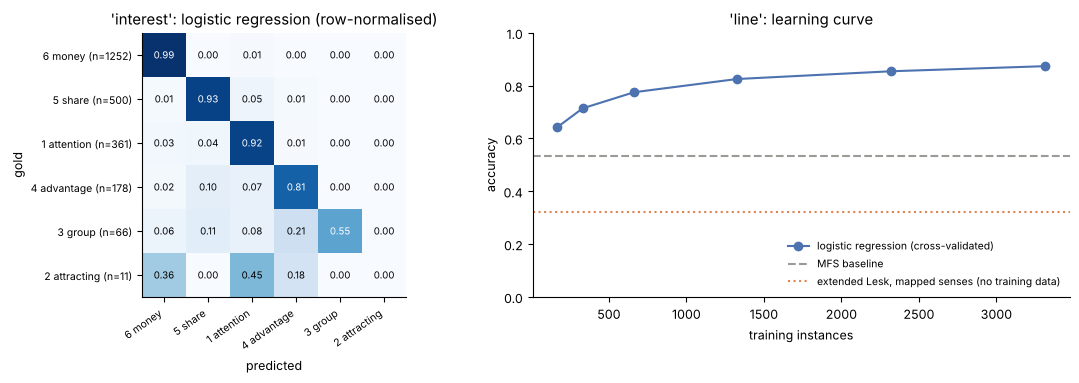

learning curve (line): 165 -> 0.642, 331 -> 0.714, 663 -> 0.775, 1326 -> 0.825, 2321 -> 0.855, 3316 -> 0.874


In [17]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.9), gridspec_kw={"width_ratios": [1, 1.15]})
y, pred = SV["interest"]["y"], PRED[("interest", "Logistic regression")]
labels = sorted(set(y), key=lambda s: -Counter(y)[s])
cm = confusion_matrix(y, pred, labels=labels)
cmn = cm / cm.sum(1, keepdims=True)
ax[0].imshow(cmn, cmap="Blues", vmin=0, vmax=1)
short = {"interest_1": "1 attention", "interest_2": "2 attracting", "interest_3": "3 group", "interest_4": "4 advantage",
         "interest_5": "5 share", "interest_6": "6 money"}
ax[0].set_xticks(range(len(labels))); ax[0].set_xticklabels([short[l] for l in labels], rotation=35, ha="right", fontsize=7.5)
ax[0].set_yticks(range(len(labels))); ax[0].set_yticklabels([f"{short[l]} (n={Counter(y)[l]})" for l in labels], fontsize=7.5)
for i in range(len(labels)):
    for j in range(len(labels)):
        ax[0].text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white" if cmn[i, j] > 0.5 else "black")
ax[0].set_xlabel("predicted"); ax[0].set_ylabel("gold"); ax[0].set_title("'interest': logistic regression (row-normalised)")
sizes, tr_sc, te_sc = learning_curve(make_pipeline(DictVectorizer(), LogisticRegression(C=2.0, max_iter=3000)), SV["line"]["X"],
                                     SV["line"]["y"], cv=cv, train_sizes=[0.05, 0.1, 0.2, 0.4, 0.7, 1.0], scoring="accuracy",
                                     shuffle=True, random_state=SEED)
ax[1].plot(sizes, te_sc.mean(1), "o-", color="#4c72b0", label="logistic regression (cross-validated)")
ax[1].axhline(SUP_TABLE.loc["MFS baseline", "line"], color="#9a9a96", ls="--", label="MFS baseline")
ax[1].axhline(KB.loc["Extended Lesk, mapped senses only (WordNet)", "line"], color="#dd8452", ls=":", label="extended Lesk, mapped senses (no training data)")
ax[1].set_xlabel("training instances"); ax[1].set_ylabel("accuracy"); ax[1].set_ylim(0, 1)
ax[1].set_title("'line': learning curve"); ax[1].legend(frameon=False, fontsize=7.5, loc="lower right")
plt.tight_layout(); fig.savefig(OUT / "supervised_wsd.png", dpi=200, bbox_inches="tight"); plt.show()
print("learning curve (line):", ", ".join(f"{n} -> {s:.3f}" for n, s in zip(sizes, te_sc.mean(1))))

In [18]:
pipe = make_pipeline(DictVectorizer(), LogisticRegression(C=2.0, max_iter=3000)).fit(SV["line"]["X"], SV["line"]["y"])
vec, clf = pipe.named_steps["dictvectorizer"], pipe.named_steps["logisticregression"]
feat = np.array(vec.get_feature_names_out())
print("Most indicative features per sense of 'line' (logistic-regression weights):")
pd.DataFrame({c: [f.replace("bow=", "") for f in feat[np.argsort(-clf.coef_[k])[:8]]] for k, c in enumerate(clf.classes_)})

Most indicative features per sense of 'line' (logistic-regression weights):


,cord,division,formation,phone,product,text
0,boat,draw,w-1=in,w-2w-1=on_the,w+1=of,w+1=about
1,hang,w+1=between,stand,telephone,p-1=NNP,deliver
2,wash,cross,long,phone,sale,write
3,fish,walk,w-1=long,call,product,w+1=like
4,clothes,class,form,open,sell,read
5,hook,w-2w-1=over_the,wait,w-1=telephone,toy,w-1=opening
6,pull,p-1=JJ,p-1=IN,dead,ibm,borrow
7,p-1=PRP$,divide,checkout,access,introduce,dialogue


## 7. Word sense induction (WSI)

WSI discovers senses **without a dictionary or labels**. It follows the distributional hypothesis: occurrences used in the same sense appear among similar words. The contexts of a word are clustered, and each cluster is an induced sense.

Method:
1. represent every occurrence by the lemmas of the content words within ±10 tokens, weighted with TF-IDF;
2. reduce to 100 dimensions with truncated SVD (latent semantic analysis), so that related words such as *telephone*, *call* and *caller* share dimensions;
3. cluster with *k*-means, using *k* = the number of gold senses.

The gold labels are used **only for evaluation**:
* **V-measure** and the **adjusted Rand index** (ARI) compare the clustering with the gold senses;
* **purity** counts each cluster's majority sense as correct.

The baseline puts every occurrence in one cluster, which gives purity = MFS share and ARI = 0.

In [19]:
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import adjusted_rand_score, v_measure_score
from sklearn.preprocessing import Normalizer

def purity(y, c):
    return sum(Counter(y[c == k]).most_common(1)[0][1] for k in np.unique(c)) / len(y)

wsi_rows, WSI = [], {}
for word in ["line", "interest", "serve", "hard"]:
    d = SV[word]
    docs = [" ".join(k[4:] for k, v in f.items() if k.startswith("bow=") for _ in range(int(v))) for f in d["X"]]
    X = TfidfVectorizer(min_df=3, sublinear_tf=True).fit_transform(docs)
    Z = Normalizer().fit_transform(TruncatedSVD(100, random_state=SEED).fit_transform(X))
    k = len(set(d["y"]))
    c = KMeans(k, n_init=10, random_state=SEED).fit_predict(Z)
    WSI[word] = (c, docs)
    wsi_rows.append({"word": word, "senses (k)": k, "V-measure": v_measure_score(d["y"], c), "ARI": adjusted_rand_score(d["y"], c),
                     "purity": purity(d["y"], c), "one-cluster purity (MFS)": Counter(d["y"]).most_common(1)[0][1] / len(d["y"])})
WSI_RES = pd.DataFrame(wsi_rows).set_index("word").round(3)
WSI_RES.to_csv(OUT / "wsi_results.csv")
WSI_RES

,senses (k),V-measure,ARI,purity,one-cluster purity (MFS)
word,,,,,
line,6,0.210,0.128,0.585,0.535
interest,6,0.231,0.076,0.598,0.529
serve,4,0.306,0.167,0.586,0.414
hard,3,0.018,-0.079,0.797,0.797


In [20]:
c, docs = WSI["line"]
y = SV["line"]["y"]
words_by_cluster = defaultdict(Counter)
for doc, k in zip(docs, c):
    words_by_cluster[k].update(set(doc.split()))
df_all = Counter(w for doc in docs for w in set(doc.split()))
rows = []
for k in sorted(words_by_cluster, key=lambda k: -np.sum(c == k)):
    n = np.sum(c == k)
    distinct = sorted(words_by_cluster[k], key=lambda w: -(words_by_cluster[k][w] / n) * math.log(len(docs) / df_all[w]))[:8]
    comp = Counter(y[c == k]).most_common(2)
    rows.append({"induced sense": f"cluster {k}", "size": n, "characteristic words": ", ".join(distinct),
                 "majority gold sense": f"{comp[0][0]} ({comp[0][1] / n:.0%})", "second": f"{comp[1][0]} ({comp[1][1] / n:.0%})" if len(comp) > 1 else ""})
print("Induced senses of 'line' (k-means on LSA vectors of the contexts):")
pd.DataFrame(rows)

Induced senses of 'line' (k-means on LSA vectors of the contexts):


,induced sense,size,characteristic words,majority gold sense,second
0,cluster 5,1536,"long, get, wait, telephone, go, end, people, call",cord (23%),formation (17%)
1,cluster 0,1326,"product, company, year, sale, include, sell, business, market",product (86%),phone (5%)
2,cluster 2,408,"say, company, mr, product, sell, spokesman, analyst, source",product (61%),phone (11%)
3,cluster 1,367,"new, car, product, york, ibm, company, year, introduce",product (80%),phone (12%)
4,cluster 4,293,"computer, personal, new, corp, ibm, machine, frasl, international",product (92%),phone (6%)
5,cluster 3,216,"draw, mr, somewhere, speech, fine, leader, president, say",division (57%),text (19%)


## 8. Error analysis

Accuracy alone does not explain *why* the methods fail, so the errors of the best knowledge-based method on SemCor are inspected below. For every wrong answer we measure how far the predicted sense is from the gold sense in WordNet: are they *near-misses* between closely related senses, or *unrelated* senses?

In [21]:
best_m = "Extended Lesk + prior (tuned)"
errs = []
for x, ok in zip(SEMCOR, results[best_m]):
    if not ok and x["n_senses"] > 1:
        pred = METHODS[best_m](x["lemma"], x["pos"], x["context"])
        sim = pred.wup_similarity(x["gold"]) if x["pos"] in (wn.NOUN, wn.VERB) else None
        errs.append({"lemma": x["lemma"], "pos": x["pos"], "senses": x["n_senses"], "gold": x["gold"].name(), "predicted": pred.name(),
                     "gold gloss": x["gold"].definition()[:55], "predicted gloss": pred.definition()[:55], "WuP(gold, pred)": sim,
                     "predicted MFS": candidates(x["lemma"], x["pos"])[0] == pred})
ERR = pd.DataFrame(errs)
nv = ERR.dropna(subset=["WuP(gold, pred)"])
print(f"{len(ERR)} errors on ambiguous instances ({len(ERR) / is_amb.sum():.1%}).")
print(f"  in {ERR['predicted MFS'].mean():.0%} of the errors the method answered with the most frequent sense while the gold "
      f"sense was a rarer one; in the other {1 - ERR['predicted MFS'].mean():.0%} context words pulled it to a wrong rarer sense")
print(f"  nouns/verbs: median Wu-Palmer similarity between predicted and gold sense = {nv['WuP(gold, pred)'].median():.2f}; "
      f"{(nv['WuP(gold, pred)'] >= 0.5).mean():.0%} of errors are near-misses (WuP >= 0.5)")
print("\nWords with the most errors:", ", ".join(f"{w} ({n})" for w, n in ERR.lemma.value_counts().head(10).items()))
ERR.to_csv(OUT / "semcor_errors.csv", index=False)
print("\nExamples of errors on frequent words:")
ERR[ERR.lemma.isin(ERR.lemma.value_counts().head(4).index)].drop_duplicates(["lemma", "gold", "predicted"]).head(8)[
    ["lemma", "senses", "gold", "gold gloss", "predicted", "predicted gloss"]]

2255 errors on ambiguous instances (32.8%).
  in 97% of the errors the method answered with the most frequent sense while the gold sense was a rarer one; in the other 3% context words pulled it to a wrong rarer sense
  nouns/verbs: median Wu-Palmer similarity between predicted and gold sense = 0.33; 30% of errors are near-misses (WuP >= 0.5)

Words with the most errors: be (115), have (66), game (33), make (25), get (24), now (20), give (19), play (19), say (18), end (16)

Examples of errors on frequent words:


,lemma,senses,gold,gold gloss,predicted,predicted gloss
5,have,19,own.v.01,have ownership or possession of,have.v.01,"have or possess, either in a concrete or an abstract se"
20,have,19,get.v.03,cause to move; cause to be in a certain position or con,have.v.01,"have or possess, either in a concrete or an abstract se"
41,be,13,be.v.02,be identical to; be someone or something,be.v.01,"have the quality of being; (copula, used with an adject"
76,be,13,be.v.03,occupy a certain position or area; be somewhere,be.v.01,"have the quality of being; (copula, used with an adject"
77,be,13,be.v.08,"work in a specific place, with a specific subject, or i",be.v.01,"have the quality of being; (copula, used with an adject"
99,be,13,be.v.05,"happen, occur, take place",be.v.01,"have the quality of being; (copula, used with an adject"
103,make,49,cause.v.01,"give rise to; cause to happen or occur, not always inte",make.v.01,engage in
125,be,13,constitute.v.01,form or compose,be.v.01,"have the quality of being; (copula, used with an adject"


## 9. Findings, limitations and possible extensions

**Sense inventory and relations.**
* The eight target words have 91 WordNet senses between them, from 4 for *plant* to 30 for *line*.
* WordNet is very fine-grained. Many senses never occur in SemCor (*bank* has 10 senses, but only 4 are attested), and closely related senses differ only slightly (*line.n.01* "one beside another" vs *line.n.03* "one behind another").
* The relations separate the homonyms clearly. The two main senses of *bank* sit in different branches of the hierarchy: *slope → geological formation* vs *financial institution → organization*. Their Wu–Palmer similarity to *slope* is 0.91 vs 0.15.

**Sample sentences.**
* Extended Lesk got **10/16** sample sentences right, simplified Lesk 8, similarity 7 and MFS 5. The sentences were written so that half of them use a non-dominant sense, so MFS is bound to miss those.
* Adding related glosses was what fixed *crane* (bird), *serve* (food, office) and *bank* (financial).
* Several failures are informative:
  * The *bass* sentences fail because the fish sense *sea_bass.n.01* ("the lean flesh of a saltwater fish") wins over the gold animal sense, and the instrument sense loses to the music senses. WordNet splits the fish and the music meanings into several near-identical senses.
  * *plant* as a living plant fails because the context words (*water, leaves, roots*) do not occur in *plant.n.02*'s gloss.

**SemCor (6,881 ambiguous instances).**
* **MFS is the strongest single method (66.3%).** Simplified Lesk reaches only 50.4%, extended Lesk 55.1% and Wu–Palmer similarity 46.0% (random: 22.6%).
* Inside Lesk, **IDF weighting helps**: gloss-only Lesk with IDF reaches 58.6%. Adding related glosses *without* the frequency prior **hurts** on running text (55.1%), because larger signatures produce more chance overlaps.
* Combining extended Lesk with a log-frequency prior, with its two parameters tuned on separate development files, gives **67.2%**, the best result, slightly above MFS. Knowledge from the glosses and frequency are complementary.
* **Verbs are hardest** (55.5% even for the best method). Accuracy falls steadily as the number of senses grows.

**Supervised vs. knowledge-based (line / interest / serve / hard).**
* With a few thousand labelled examples per word, Naive Bayes and logistic regression reach **91–93% accuracy**, against 57% for the MFS baseline. Macro-F1 rises from 0.17 to about 0.83, so the rare senses are learnt too.
* The learning curve for *line* beats MFS with only 165 training examples.
* Knowledge-based methods on the same data reach only **24% (open) to 33% (restricted to the mapped senses)**. The frequency prior even *lowers* accuracy here (15%): SemCor's most frequent senses are the wrong ones for these mostly business-newswire texts, where *line* usually means a product line and *interest* an interest rate.
* Labelled, in-domain data is worth far more than the dictionary. But it has to be collected separately for every word, and that is why all-words WSD still relies on WordNet.

**Sense induction.**
* Clustering contexts without labels finds the dominant, topical senses: the product clusters of *line* (IBM, computer, sale) and a *division* cluster (draw, fine, leader).
* It agrees only weakly with the gold senses (V-measure 0.21–0.31, purity a few points above MFS), and it fails for *hard* (V-measure 0.02). Topic words separate homonyms but not senses that differ in syntax or nuance.

**Error analysis.**
* 97% of the best method's SemCor errors are cases where it answered with the most frequent sense and the gold sense was a rarer one. Context evidence too rarely overrides the prior.
* Errors concentrate on very frequent, highly polysemous verbs (*be, have, make, get, give*). For nouns and verbs, 30% of the errors are near-misses (Wu–Palmer ≥ 0.5 between predicted and gold sense), which would count as correct under a coarser sense inventory.

**Limitations.**
* The gold lemma and POS are given in the SemCor evaluation.
* MFS benefits from WordNet's frequencies, which were counted on SemCor itself.
* The sample sentences were written for this lab and are few.
* The WordNet mapping for the lexical-sample corpora is our own.
* WSI uses only bag-of-words contexts, and k is set to the gold number of senses.

**Possible extensions.**
* Coarse-grained evaluation (sense clusters or WordNet domains).
* Lesk with word embeddings: similarity between gloss and context instead of exact overlap.
* Graph-based WSD (Personalized PageRank over WordNet).
* Contextual embeddings (BERT) with nearest-sense matching trained on SemCor.
* WSI with contextual embeddings and automatic choice of k.